In [1]:
import pandas as pd
import numpy as np

In [2]:
# # Đọc dữ liệu M5
# sales_df = pd.read_csv('./data/sales_train_validation.csv')
# calendar_df = pd.read_csv('./data/calendar.csv')

# # Chuyển dữ liệu sales từ wide format sang long format
# sales_melted = pd.melt(
#     sales_df,
#     id_vars=['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id'],
#     var_name='d',
#     value_name='sales'
# )

In [3]:
# # Ghép với calendar để lấy ngày thực tế
# sales_with_date = sales_melted.merge(calendar_df[['d', 'date']], on='d', how='left')

# # Chuyển cột date sang định dạng datetime
# sales_with_date['date'] = pd.to_datetime(sales_with_date['date'])

# # Xem trước
# sales_with_date.head()

In [4]:
# sales_with_date.to_csv('./data/sales_with_date.csv')

In [5]:
# Đọc dữ liệu disaster
disaster_df = pd.read_csv('data/us_disasters_m5.csv', parse_dates=[
    'declaration_date', 'incident_begin_date', 'incident_end_date'])

# Lọc năm >= 2011 và chỉ lấy một vài dòng (demo)
disaster_df = disaster_df[disaster_df['declaration_date'].dt.year >= 2011]
disaster_df = disaster_df.rename(columns={
    'declaration_date': 'date',
    'state': 'state_id',
    'incident_type': 'disaster_type'
})
disaster_df = disaster_df[disaster_df['state_id'].isin(['CA', 'TX', 'WI'])].head(10)  # chỉ lấy 10 dòng demo

# Load một phần sales (ví dụ vài ngàn dòng đầu tiên)
sales_with_date = pd.read_csv('data/sales_with_date.csv', parse_dates=['date']).head(500)
sales_with_date['date'] = sales_with_date['date'].dt.tz_localize(None)

disaster_df['date'] = disaster_df['date'].dt.tz_localize(None)
disaster_df['incident_begin_date'] = disaster_df['incident_begin_date'].dt.tz_localize(None)
disaster_df['incident_end_date'] = disaster_df['incident_end_date'].dt.tz_localize(None)


# Merge cơ bản theo ngày công bố
merged_df = pd.merge(
    sales_with_date,
    disaster_df[['date', 'state_id', 'disaster_type']],
    on=['date', 'state_id'],
    how='left'
)

merged_df['disaster_type'] = merged_df['disaster_type'].fillna('No Disaster')
merged_df['in_disaster_period'] = False

# Đánh dấu những dòng nằm trong khoảng thời gian thảm họa
for _, row in disaster_df.iterrows():
    mask = (
        (merged_df['date'] >= row['incident_begin_date']) &
        (merged_df['date'] <= row['incident_end_date']) &
        (merged_df['state_id'] == row['state_id'])
    )
    merged_df.loc[mask, 'in_disaster_period'] = True

# Xem trước kết quả
print(merged_df.head(10))
print("\nThống kê disaster:")
print(merged_df['in_disaster_period'].value_counts())

   Unnamed: 0                             id        item_id    dept_id  \
0           0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1   
1           1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1   
2           2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1   
3           3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1   
4           4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1   
5           5  HOBBIES_1_006_CA_1_validation  HOBBIES_1_006  HOBBIES_1   
6           6  HOBBIES_1_007_CA_1_validation  HOBBIES_1_007  HOBBIES_1   
7           7  HOBBIES_1_008_CA_1_validation  HOBBIES_1_008  HOBBIES_1   
8           8  HOBBIES_1_009_CA_1_validation  HOBBIES_1_009  HOBBIES_1   
9           9  HOBBIES_1_010_CA_1_validation  HOBBIES_1_010  HOBBIES_1   

    cat_id store_id state_id    d  sales       date disaster_type  \
0  HOBBIES     CA_1       CA  d_1      0 2011-01-29   No Disaster   
1  HOBBIES     CA_1       CA  d_1      0 2011-0

In [7]:
import pandas as pd

# Tải các file dữ liệu
sales_train_val = pd.read_csv('./data/sales_train_validation.csv').head(200)
sell_prices = pd.read_csv('./data/sell_prices.csv').head(200)
calendar = pd.read_csv('./data/calendar.csv').head(200)

# Xem thông tin cơ bản của dữ liệu
print("Sales Train Validation:")
print(sales_train_val.info())
print(sales_train_val.head())

print("\nSell Prices:")
print(sell_prices.info())
print(sell_prices.head())

print("\nCalendar:")
print(calendar.info())
print(calendar.head())

Sales Train Validation:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Columns: 1919 entries, id to d_1913
dtypes: int64(1913), object(6)
memory usage: 2.9+ MB
None
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id  d_1  d_2  d_3  d_4  ...  d_1904  d_1905  d_1906  d_1907  d_1908  \
0       CA    0    0    0    0  ...       1       3       0       1       1   
1       CA    0    0    0    0  ...       0       0       0       0       0   
2       CA    0    0    0    0  ...       2       1       2       1       1   
3       CA   

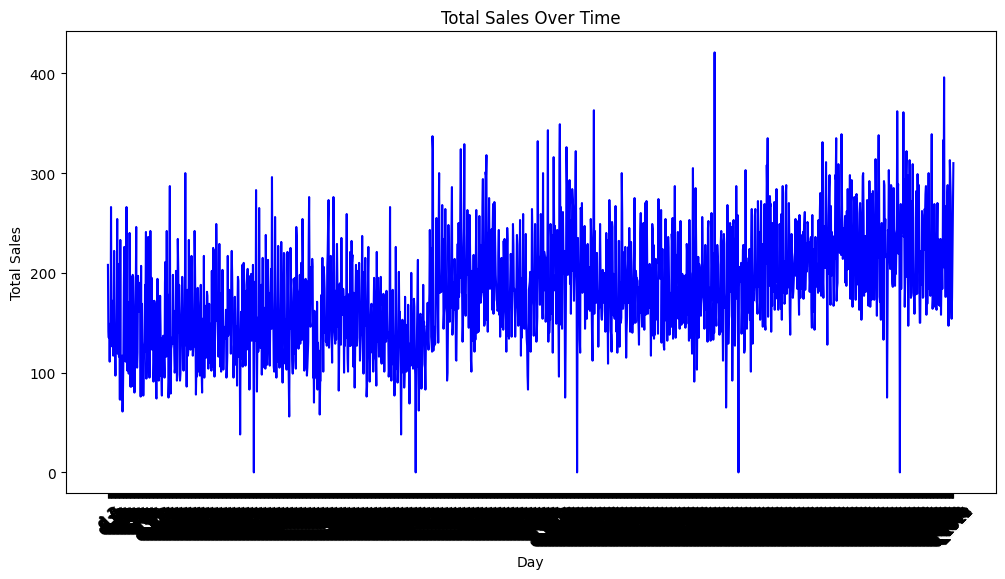

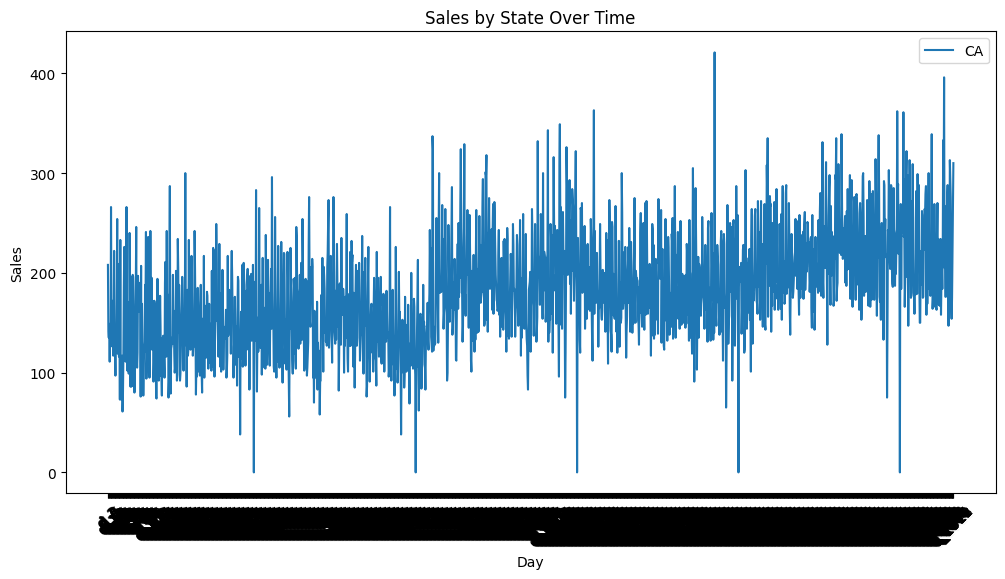

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Tổng hợp doanh số theo ngày (loại bỏ các cột không phải ngày)
day_columns = [col for col in sales_train_val.columns if col.startswith('d_')]
sales_by_day = sales_train_val[day_columns].sum()

# Chuyển đổi thành DataFrame để vẽ biểu đồ
sales_by_day_df = pd.DataFrame({'Day': day_columns, 'Sales': sales_by_day})

# Vẽ biểu đồ doanh số theo ngày
plt.figure(figsize=(12, 6))
plt.plot(sales_by_day_df['Day'], sales_by_day_df['Sales'], color='blue')
plt.title('Total Sales Over Time')
plt.xlabel('Day')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

# Phân tích doanh số theo bang (state)
sales_by_state = sales_train_val.groupby('state_id')[day_columns].sum().T
plt.figure(figsize=(12, 6))
for state in sales_by_state.columns:
    plt.plot(sales_by_state.index, sales_by_state[state], label=state)
plt.title('Sales by State Over Time')
plt.xlabel('Day')
plt.ylabel('Sales')
plt.legend()
plt.xticks(rotation=45)
plt.show()

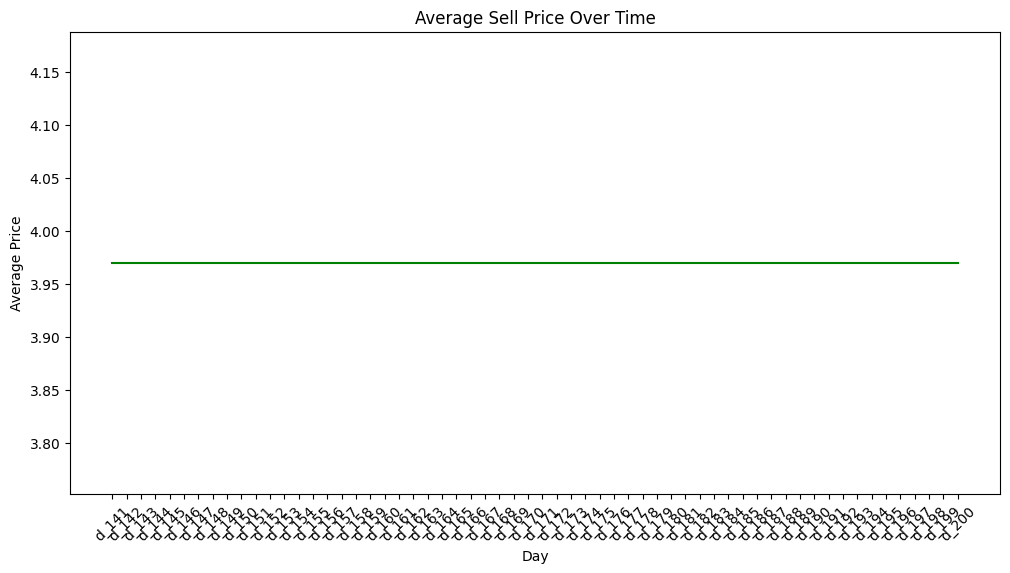

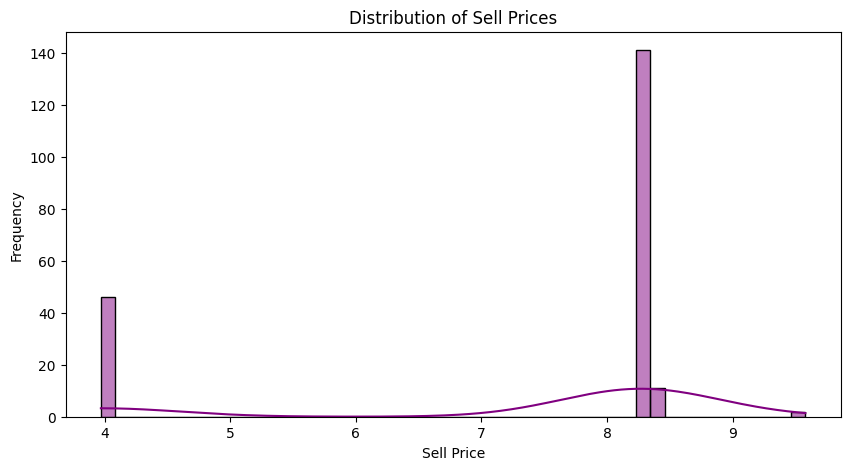

In [10]:
# Tính giá bán trung bình theo tuần
sell_prices_with_calendar = sell_prices.merge(calendar[['wm_yr_wk', 'd']], 
                                              on='wm_yr_wk', how='left')
avg_price_by_day = sell_prices_with_calendar.groupby('d')['sell_price'].mean()

# Vẽ biểu đồ giá trung bình theo ngày
plt.figure(figsize=(12, 6))
plt.plot(avg_price_by_day.index, avg_price_by_day.values, color='green')
plt.title('Average Sell Price Over Time')
plt.xlabel('Day')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()

# Phân tích phân phối giá bán
plt.figure(figsize=(10, 5))
sns.histplot(sell_prices['sell_price'], bins=50, kde=True, color='purple')
plt.title('Distribution of Sell Prices')
plt.xlabel('Sell Price')
plt.ylabel('Frequency')
plt.show()

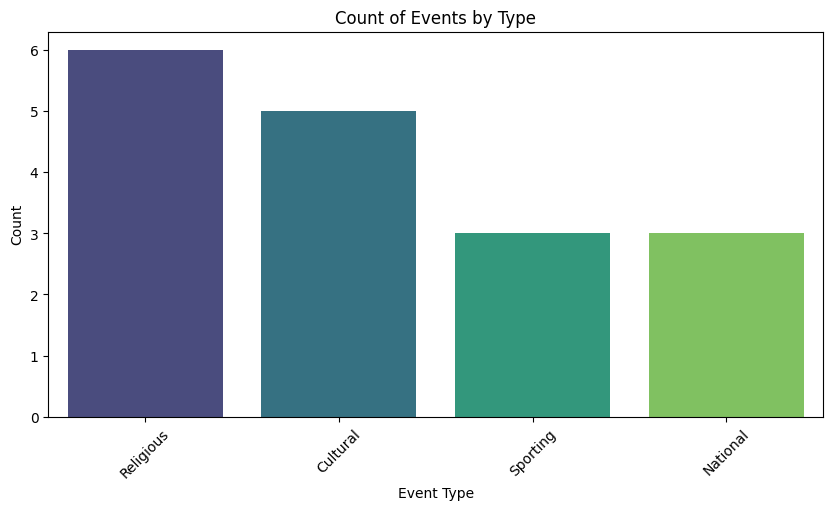

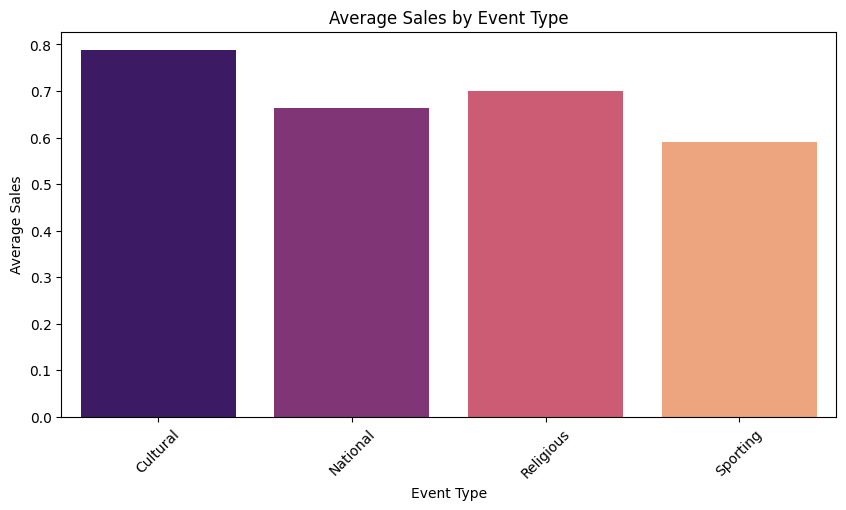

In [11]:
# Đếm số lượng sự kiện theo loại
event_counts = calendar['event_type_1'].value_counts(dropna=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=event_counts.index, y=event_counts.values, palette='viridis')
plt.title('Count of Events by Type')
plt.xlabel('Event Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

# Kết hợp dữ liệu lịch với doanh số để phân tích ảnh hưởng của sự kiện
sales_with_calendar = pd.melt(sales_train_val, id_vars=['id'], 
                              value_vars=day_columns, var_name='d', value_name='sales')
sales_with_events = sales_with_calendar.merge(calendar[['d', 'event_type_1']], 
                                              on='d', how='left')

# So sánh doanh số trung bình có/không có sự kiện
sales_by_event = sales_with_events.groupby('event_type_1')['sales'].mean()
plt.figure(figsize=(10, 5))
sns.barplot(x=sales_by_event.index, y=sales_by_event.values, palette='magma')
plt.title('Average Sales by Event Type')
plt.xlabel('Event Type')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()

In [14]:
disaster_df.columns

Index(['disaster_number', 'state_id', 'declaration_type', 'date',
       'disaster_type', 'declaration_title', 'ih_program_declared',
       'ia_program_declared', 'pa_program_declared', 'hm_program_declared',
       'incident_begin_date', 'incident_end_date', 'fips', 'designated_area'],
      dtype='object')

In [ ]:
calendar.columns

Index(['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd',
       'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2',
       'snap_CA', 'snap_TX', 'snap_WI'],
      dtype='object')

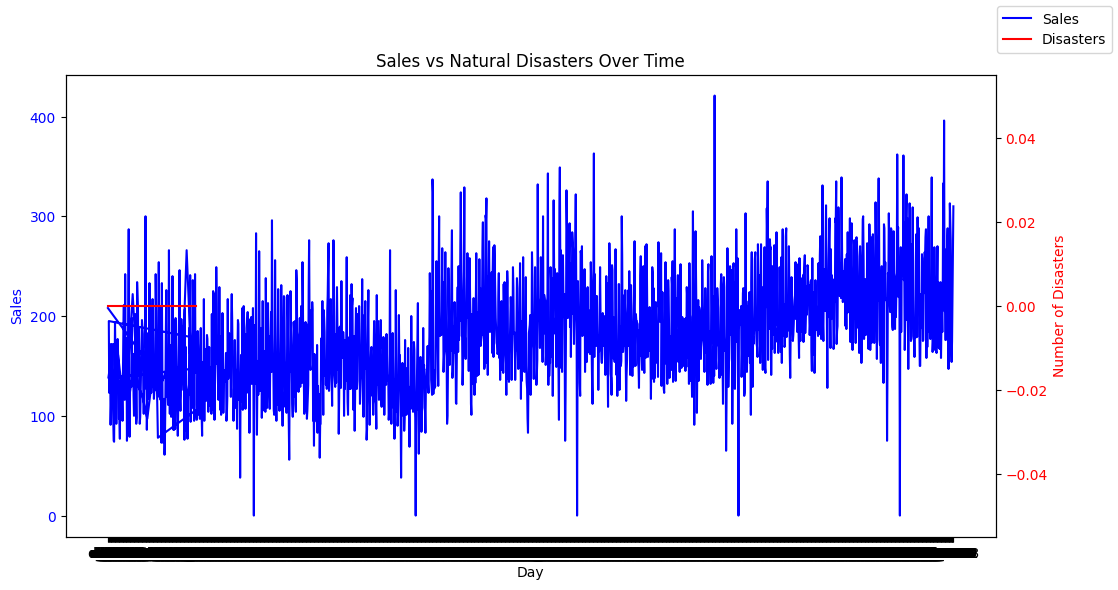

In [18]:
calendar['date'] = sales_with_date['date'].dt.tz_localize(None)
disaster_df['date'] = disaster_df['date'].dt.tz_localize(None)
disaster_df['incident_begin_date'] = disaster_df['incident_begin_date'].dt.tz_localize(None)
disaster_df['incident_end_date'] = disaster_df['incident_end_date'].dt.tz_localize(None)


# Kết hợp dữ liệu thiên tai với lịch dựa trên cột 'date'
calendar_with_disasters = calendar.merge(disaster_df, on='date', how='left')

# Tính tổng số thiên tai theo ngày (dùng cột 'd' từ calendar)
disaster_counts = calendar_with_disasters.groupby('d')['disaster_type'].count()

# Vẽ biểu đồ doanh số và số lượng thiên tai
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(sales_by_day_df['Day'], sales_by_day_df['Sales'], color='blue', label='Sales')
ax1.set_xlabel('Day')
ax1.set_ylabel('Sales', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(disaster_counts.index, disaster_counts.values, color='red', label='Disasters')
ax2.set_ylabel('Number of Disasters', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Sales vs Natural Disasters Over Time')
fig.legend(loc='upper right')
plt.xticks(rotation=45)
plt.show()

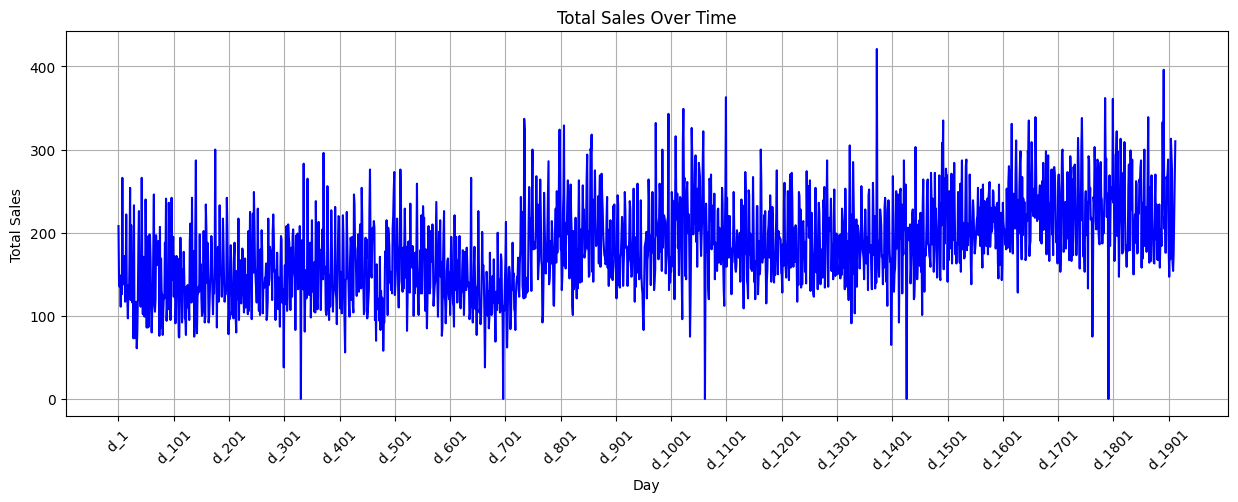

In [19]:
# Lấy các cột ngày
day_columns = [col for col in sales_train_val.columns if col.startswith('d_')]

# Tính tổng doanh số theo ngày
total_sales_by_day = sales_train_val[day_columns].sum()

# Vẽ biểu đồ
plt.figure(figsize=(15, 5))
plt.plot(total_sales_by_day.index, total_sales_by_day.values, color='blue')
plt.title('Total Sales Over Time')
plt.xlabel('Day')
plt.ylabel('Total Sales')
plt.xticks(range(0, len(day_columns), 100), rotation=45)  # Hiển thị nhãn cách 100 ngày
plt.grid(True)
plt.show()

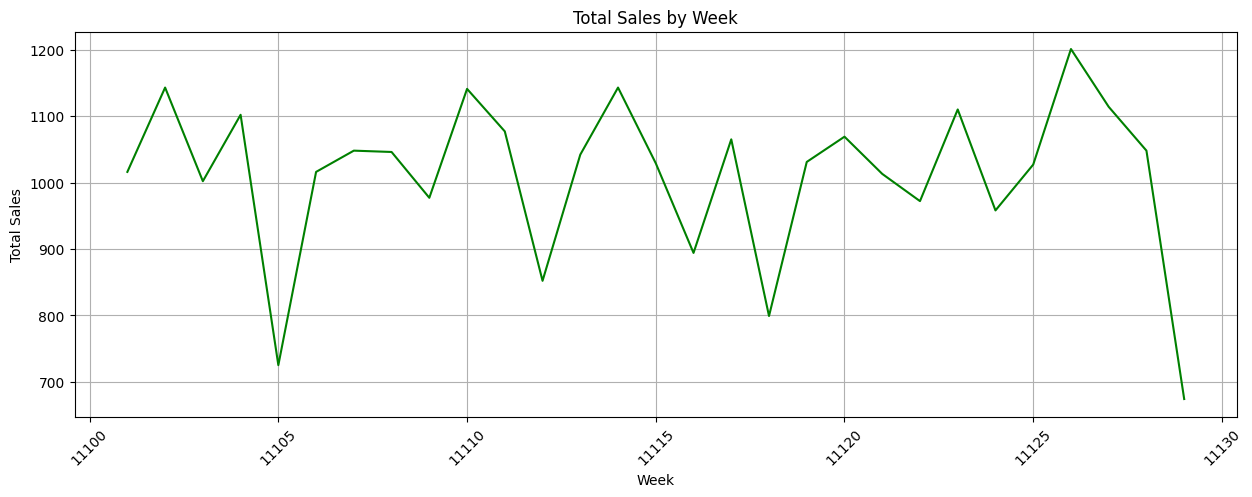

In [20]:
# Chuyển đổi dữ liệu doanh số sang dạng dài
sales_melted = pd.melt(sales_train_val, id_vars=['id'], value_vars=day_columns, 
                       var_name='d', value_name='sales')

# Kết hợp với dữ liệu lịch để lấy tuần
sales_with_calendar = sales_melted.merge(calendar[['d', 'wm_yr_wk']], on='d', how='left')

# Tổng hợp doanh số theo tuần
weekly_sales = sales_with_calendar.groupby('wm_yr_wk')['sales'].sum()

# Vẽ biểu đồ
plt.figure(figsize=(15, 5))
plt.plot(weekly_sales.index, weekly_sales.values, color='green')
plt.title('Total Sales by Week')
plt.xlabel('Week')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

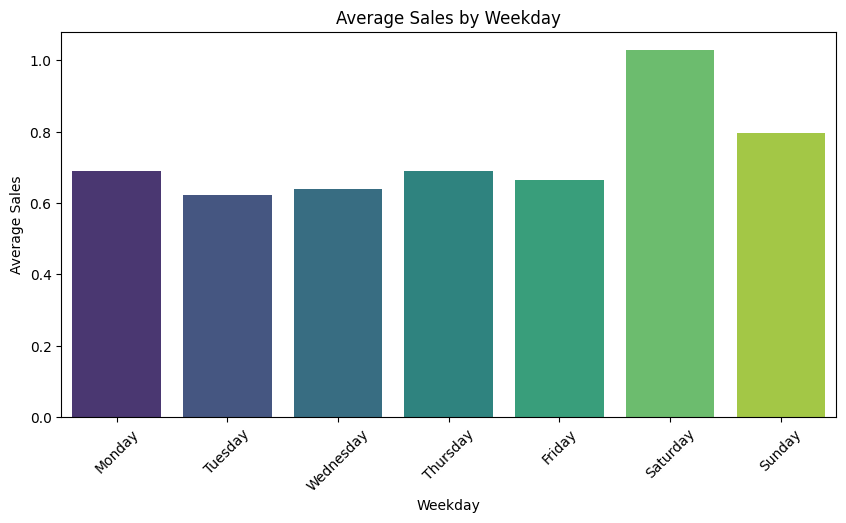

In [21]:
import seaborn as sns

# Kết hợp dữ liệu doanh số với ngày trong tuần từ calendar
sales_with_weekday = sales_melted.merge(calendar[['d', 'weekday']], on='d', how='left')

# Tính doanh số trung bình theo ngày trong tuần
avg_sales_by_weekday = sales_with_weekday.groupby('weekday')['sales'].mean()

# Đảm bảo thứ tự ngày trong tuần
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
avg_sales_by_weekday = avg_sales_by_weekday.reindex(weekday_order)

# Vẽ biểu đồ
plt.figure(figsize=(10, 5))
sns.barplot(x=avg_sales_by_weekday.index, y=avg_sales_by_weekday.values, palette='viridis')
plt.title('Average Sales by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()

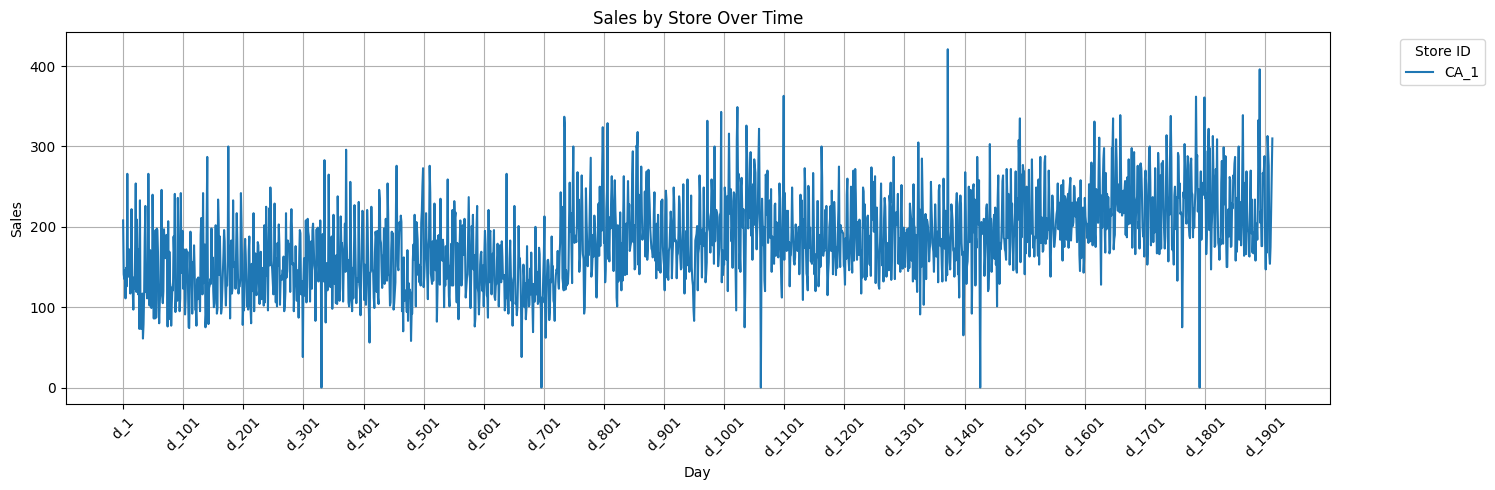

In [22]:
# Tổng hợp doanh số theo cửa hàng
sales_by_store = sales_train_val.groupby('store_id')[day_columns].sum().T

# Vẽ biểu đồ
plt.figure(figsize=(15, 5))
for store in sales_by_store.columns:
    plt.plot(sales_by_store.index, sales_by_store[store], label=store)
plt.title('Sales by Store Over Time')
plt.xlabel('Day')
plt.ylabel('Sales')
plt.legend(title='Store ID', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(range(0, len(day_columns), 100), rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

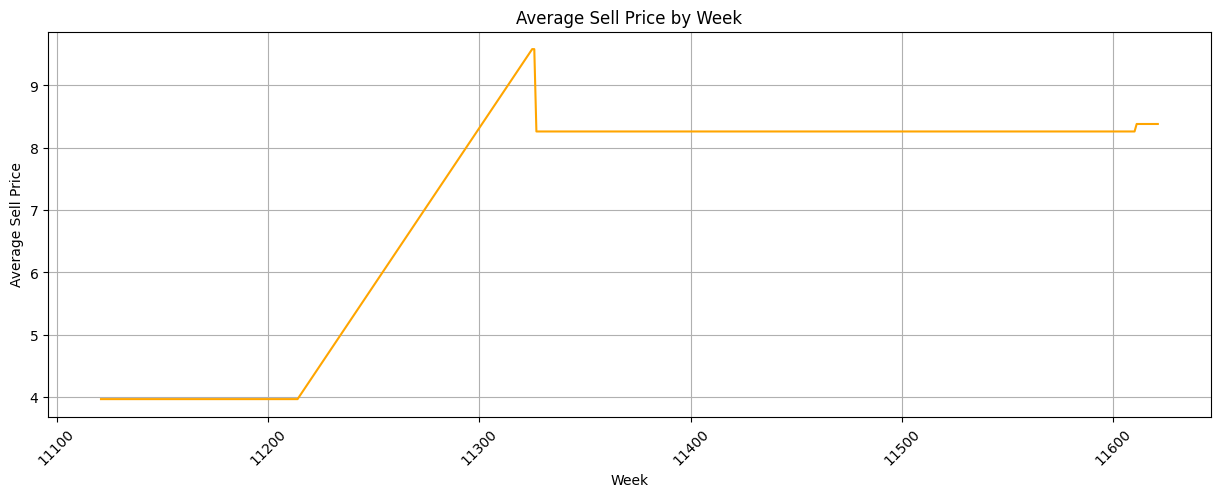

In [24]:
# Kết hợp dữ liệu giá bán với tuần từ calendar
sell_prices_with_week = sell_prices.merge(calendar[['wm_yr_wk', 'd']], on='wm_yr_wk', how='left')

# Tính giá bán trung bình theo tuần
avg_price_by_week = sell_prices_with_week.groupby('wm_yr_wk')['sell_price'].mean()

# Vẽ biểu đồ
plt.figure(figsize=(15, 5))
plt.plot(avg_price_by_week.index, avg_price_by_week.values, color='orange')
plt.title('Average Sell Price by Week')
plt.xlabel('Week')
plt.ylabel('Average Sell Price')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

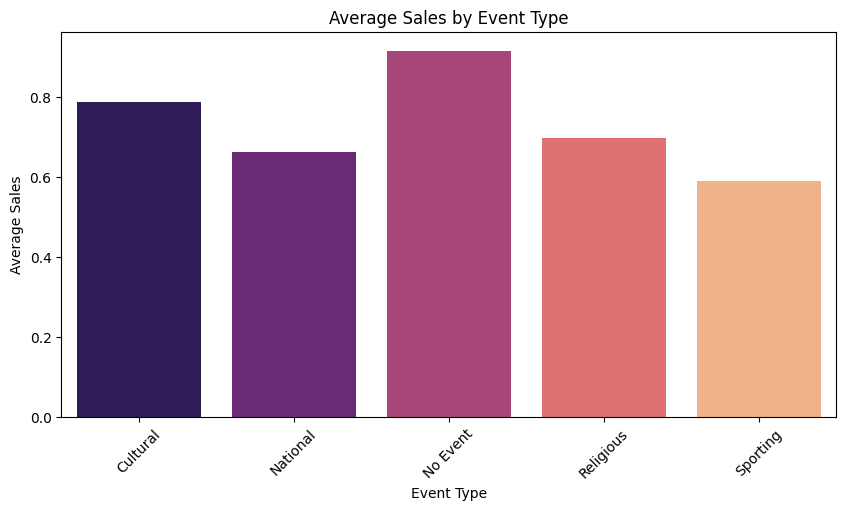

In [26]:
# Kết hợp dữ liệu doanh số với sự kiện từ calendar
sales_with_events = sales_melted.merge(calendar[['d', 'event_type_1']], on='d', how='left')

# Thay NaN trong event_type_1 thành 'No Event'
sales_with_events['event_type_1'] = sales_with_events['event_type_1'].fillna('No Event')

# Tính doanh số trung bình theo loại sự kiện
avg_sales_by_event = sales_with_events.groupby('event_type_1')['sales'].mean()

# Vẽ biểu đồ
plt.figure(figsize=(10, 5))
sns.barplot(x=avg_sales_by_event.index, y=avg_sales_by_event.values, palette='magma')
plt.title('Average Sales by Event Type')
plt.xlabel('Event Type')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.show()